# 5. Reprints: do a few works account for most religious editions?

If most spiritual or preaching editions were reprints of a handful of works (Ignatius's *Spiritual Exercises*, Granada's
*Guía de pecadores*…), close reading of those few works would cover the field. Here I measure how concentrated the editions are.

**Work:** I group editions with the same author surname and the same first three words of the title, after dropping openings such
as "Libro llamado", "Primera parte de", "Tratado de" ("Primera parte del libro llamado Guía de pecadores" → "granada | guia pecadores …").
Editions without an author are grouped by title only. The rule is rough: it splits works whose titles vary between editions or
whose author is written in two ways, so the real concentration is somewhat higher than what I measure. Grouping by author gives
an upper bound.

Classes come from the keyword lexicon (notebook 3), the only classification that covers every record; I count catalog records,
one catalog at a time: about 22,700 BNE records describe editions that are also in the USTC.

---


# 5. Reediciones: ¿unas pocas obras concentran la mayoría de las ediciones religiosas?

Si la mayoría de las ediciones espirituales o de predicación fueran reediciones de un puñado de obras (los *Ejercicios
espirituales* de Ignacio, la *Guía de pecadores* de Granada…), la lectura cercana de esas pocas obras alcanzaría para cubrir el
campo. Acá mido cuánto se concentran las ediciones.

**Obra:** agrupo las ediciones con el mismo apellido de autor y las mismas tres primeras palabras del título, después de quitar
comienzos como "Libro llamado", "Primera parte de", "Tratado de" ("Primera parte del libro llamado Guía de pecadores" →
"granada | guia pecadores …"). Las ediciones sin autor las agrupo solo por el título. La regla es tosca: separa obras cuyos
títulos cambian de una edición a otra o cuyo autor aparece escrito de dos maneras, así que la concentración real es algo mayor
que la que mido. Agrupar por autor da una cota superior.

Las clases vienen del léxico (notebook 3), la única clasificación que cubre todos los registros; cuento registros de catálogo,
un catálogo por vez: unos 22.700 registros de la BNE describen ediciones que también están en el USTC.

In [1]:
# Celda 1
# Paths and parameters:
%cd "E:/No sincroniza/Software desarrollado/spanish-imprints-counts"
DATA = "E:/Datos/spanish_imprints"
CATALOG = DATA + "/catalog.tsv"     # From notebook 3.
FIGURES = "figures"
TOP = [5, 10, 50, 100]
MIN_PAGES = 48
# Editions per work -> bin: 1 -> "1", 2 or 3 -> "2-3", 4 to 10 -> "4-10", more -> "11+":
BINS = [(1, 1, "1"), (2, 3, "2–3"), (4, 10, "4–10"), (11, 100000, "11+")]
# Figure: black background, Montserrat, green from dark (works printed once) to light (works printed 11 times or more):
BIN_COLORS = ["#14513A", "#1F7F59", "#2DB57E", "#3AF4A0"]
WHITE = "#F2F2F2"

E:\No sincroniza\Software desarrollado\spanish-imprints-counts


In [2]:
# Celda 2
import re
import pandas as pd
import matplotlib.pyplot as plt
from lexicon import fold
plt.style.use("dark_background")
plt.rc("font", family="Montserrat")
catalog = pd.read_csv(CATALOG, sep="\t", dtype={"id": str})
catalog["author_text"] = catalog["author_text"].fillna("")
catalog["title"] = catalog["title"].fillna("")

# The two catalogs, never added up:
CATALOGS = {"USTC": catalog["source"] == "ustc", "BNE": catalog["source"] == "bne"}
# The three classes I follow (from the lexicon): spiritual, preaching, and pastoral as a whole:
CLASSES = {"Spiritual": catalog["lexicon_class"] == "spiritual",
           "Preaching": catalog["group"] == "preaching",
           "Pastoral": catalog["lexicon_class"] != "none"}
pd.DataFrame({name: [(in_class & in_catalog).sum() for in_catalog in CATALOGS.values()] for name, in_class in CLASSES.items()},
             index=list(CATALOGS))

,Spiritual,Preaching,Pastoral
USTC,5622,6189,17382
BNE,4809,4716,13719


## 1. How do I recognize a work?

---


## 1. ¿Cómo reconozco una obra?

In [3]:
# Celda 3
# "Puente, Luis de la, ( 1554-1624) /**/ Pérez de Soto, Antonio" -> "puente":
def surname(author_text):
    first = author_text.split("/**/")[0].split(";")[0]
    return fold(first.split(",")[0]).strip()

# Openings that say nothing about the work:
OPENING = re.compile(r"^(?:(?:libro|tratado|obra|primera|segunda|tercera|parte|de|del|la|el|los|las|llamad[oa]|intitulad[oa]|que|se|en|nuevo|nueva|breue|compendio|sumario|summario|i|y)\s+)+")

# "Primera parte del libro llamado Guia de pecadores" -> "guia pecadores":
def title_start(title, n_words=3):
    t = OPENING.sub("", fold(title).strip())
    words = [w for w in re.findall(r"[a-z]+", t) if len(w) > 2]
    return " ".join(words[:n_words])

catalog["author_key"] = catalog["author_text"].map(surname)
catalog["work_key"] = catalog["author_key"] + " | " + catalog["title"].map(title_start)
catalog["work_key_loose"] = catalog["author_key"] + " | " + catalog["title"].map(lambda t: title_start(t, 2))
catalog.loc[CLASSES["Spiritual"], ["author_text", "title", "work_key"]].head()

,author_text,title,work_key
0,"Meneses, Felipe de",Luz del alma christiana contra la ceguedad e i...,meneses | luz del alma
8,"Sena, Bernardino de","Ordenaciones generales para el mejor, mas faci...",sena | ordenaciones generales para
28,Thomas a Kempis,"Contemptus mundi, por su original",tomas a kempis | contemptus mundi por
29,"Osuna, Francisco de",Norte de los estados,osuna | norte los estados
34,,Preparacion para reçar el oficio divino benign...,| preparacion para recar


## 2. How many different works are there?

Two rules: author + first three words, and a looser author + first two words, which merges more reprints.

---


## 2. ¿Cuántas obras distintas hay?

Dos reglas: autor + tres primeras palabras, y otra más laxa, autor + dos primeras palabras, que junta más reediciones.

In [4]:
# Celda 4
rows = []
for catalog_name, in_catalog in CATALOGS.items():
    for name, in_class in CLASSES.items():
        for subset in ["all", f"{MIN_PAGES}+ pages"]:
            editions = catalog[in_catalog & in_class]
            if subset != "all":
                editions = editions[editions["pages"] >= MIN_PAGES]
            rows.append({"catalog": catalog_name, "class": name, "editions": subset, "count": len(editions),
                         "works (author + 3 words)": editions["work_key"].nunique(),
                         "works (author + 2 words)": editions["work_key_loose"].nunique(),
                         "editions per work": round(len(editions) / editions["work_key"].nunique(), 2)})
unique_works = pd.DataFrame(rows)
unique_works.to_csv("results/unique_works.csv", index=False)
unique_works

,catalog,class,editions,count,works (author + 3 words),works (author + 2 words),editions per work
0,USTC,Spiritual,all,5622,3376,3084,1.67
1,USTC,Spiritual,48+ pages,3295,1787,1633,1.84
2,USTC,Preaching,all,6189,5011,4570,1.24
3,USTC,Preaching,48+ pages,2214,1614,1526,1.37
4,USTC,Pastoral,all,17382,11896,10718,1.46
5,USTC,Pastoral,48+ pages,8553,5133,4748,1.67
6,BNE,Spiritual,all,4809,3324,3077,1.45
7,BNE,Spiritual,48+ pages,2692,1776,1666,1.52
8,BNE,Preaching,all,4716,4075,3852,1.16
9,BNE,Preaching,48+ pages,2277,1917,1846,1.19


## 3. What share of the editions do the most printed works and authors take?

I compute shares over all editions of the class, including those without an author (which never enter a ranking).

---


## 3. ¿Qué parte de las ediciones se llevan las obras y los autores más impresos?

Calculo los porcentajes sobre todas las ediciones de la clase, también las que no tienen autor (que nunca entran en un ranking).

In [5]:
# Celda 5
rows = []
for catalog_name, in_catalog in CATALOGS.items():
    for name, in_class in CLASSES.items():
        for subset in ["all", f"{MIN_PAGES}+ pages"]:
            editions = catalog[in_catalog & in_class]
            if subset != "all":
                editions = editions[editions["pages"] >= MIN_PAGES]
            with_author = editions[editions["author_key"] != ""]
            row = {"catalog": catalog_name, "class": name, "editions": subset, "count": len(editions)}
            for level in ["work_key", "author_key"]:
                counts = with_author[level].value_counts()
                for n in TOP:
                    row[f"top {n} {level.split('_')[0]}s"] = round(100 * counts.head(n).sum() / len(editions), 1)
            rows.append(row)
shares = pd.DataFrame(rows)
shares.to_csv("results/work_concentration.csv", index=False)
shares.set_index(["catalog", "class", "editions"]).T

catalog              USTC                                                   \
class           Spiritual           Preaching           Pastoral             
editions              all 48+ pages       all 48+ pages      all 48+ pages   
count              5622.0    3295.0    6189.0    2214.0  17382.0    8553.0   
top 5 works           4.1       5.7       2.3       6.0      1.5       2.7   
top 10 works          6.8       9.5       3.5       8.7      2.6       4.7   
top 50 works         16.9      23.3       7.7      18.0      8.0      13.7   
top 100 works        23.1      31.7      10.7      24.6     11.5      19.7   
top 5 authors        13.3      16.3       5.8      12.1      5.6       8.3   
top 10 authors       17.8      22.4       8.7      17.5      8.4      12.5   
top 50 authors       38.8      48.0      20.4      34.3     21.5      31.5   
top 100 authors      48.6      59.9      29.3      45.2     30.3      42.6   

catalog               BNE                                                   
class           Spiritual           Preaching           Pastoral            
editions              all 48+ pages       all 48+ pages      all 48+ pages  
count              4809.0    2692.0    4716.0    2277.0  13719.0    7644.0  
top 5 works           3.0       3.8       1.4       2.6      1.1       1.5  
top 10 works          4.8       6.6       2.1       4.0      1.9       2.7  
top 50 works         12.7      18.6       6.1      10.6      5.7       8.8  
top 100 works        17.6      25.6       9.2      15.5      8.6      13.3  
top 5 authors         8.5      11.5       3.9       6.1      3.6       5.0  
top 10 authors       12.7      15.9       6.0       9.1      5.9       7.7  
top 50 authors       26.5      34.7      16.0      21.5     15.5      20.5  
top 100 authors      34.7      45.8      23.3      30.7     22.1      29.2

In [6]:
# Celda 6
# The ten most printed spiritual works and preaching works in each catalog:
for catalog_name, in_catalog in CATALOGS.items():
    for name in ["Spiritual", "Preaching"]:
        editions = catalog[in_catalog & CLASSES[name] & (catalog["author_key"] != "")]
        print(catalog_name, name.upper())
        print(editions["work_key"].value_counts().head(10).to_string(), "\n")

USTC SPIRITUAL
agreda | mistica ciudad dios                       61
ualderrama | ejercicios espirituales para          52
granada | memorial uida cristiana                  41
granada | oracion meditacion                       40
uillacastin | manual ejercicios espirituales       36
nieremberg | diferencia entre temporal             35
fonseca | amor dios                                32
gueuara | monte caluario                           31
molina | ejercicios espirituales las               30
alonso rodriguez | ejercicio perfecion uirtudes    26 

USTC PREACHING
niseno | asuntos predicables para                     43
barcia i zambrana | despertador cristiano sermones    42
murillo | discursos predicables sobre                 21
florencia | sermon que predico                        20
uega | empleo ejercicio santo                         18
santiago | consideraciones sobre todos                17
auendano | sermones del aduiento                      17
barcia i zambrana | cuaresma 

## 4. How many editions belong to works printed only once?

Each edition goes to a bin according to how many editions its work has in the catalog.

---


## 4. ¿Cuántas ediciones son de obras impresas una sola vez?

Cada edición va a un grupo según cuántas ediciones tiene su obra en el catálogo.

In [7]:
# Celda 7
rows = []
for catalog_name, in_catalog in CATALOGS.items():
    for name, in_class in CLASSES.items():
        editions = catalog[in_catalog & in_class]
        editions_per_work = editions["work_key"].map(editions["work_key"].value_counts())
        row = {"catalog": catalog_name, "class": name}
        for low, high, label in BINS:
            row[label] = round(100 * ((editions_per_work >= low) & (editions_per_work <= high)).mean(), 1)
        rows.append(row)
reprints = pd.DataFrame(rows).set_index(["catalog", "class"])
reprints.to_csv("results/editions_by_reprints.csv")
reprints

1   2–3  4–10   11+
catalog class                            
USTC    Spiritual  46.7  21.8  16.0  15.5
        Preaching  71.3  18.1   6.7   3.9
        Pastoral   56.8  19.9  11.5  11.8
BNE     Spiritual  57.0  20.5  13.7   8.8
        Preaching  78.4  14.8   5.8   1.0
        Pastoral   64.5  18.4  11.5   5.6

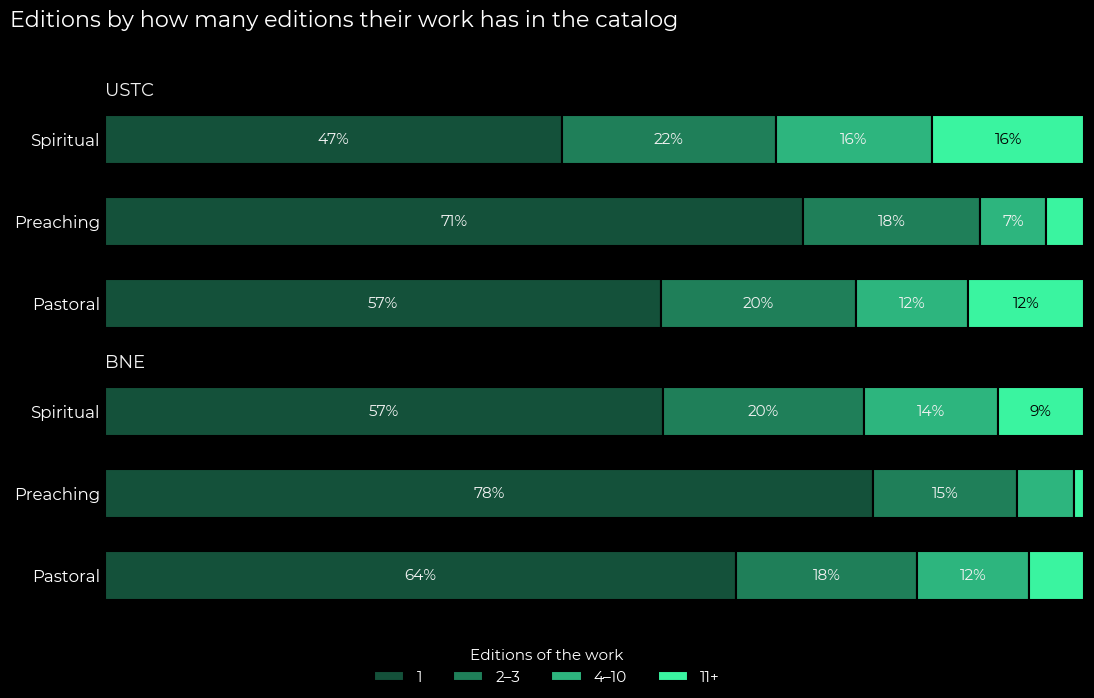

In [8]:
# Celda 8
# One panel per catalog, one bar per class, split by how many editions the work has:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for ax, catalog_name in zip(axes, CATALOGS):
    plot_data = reprints.loc[catalog_name].iloc[::-1]
    left = [0] * len(plot_data)
    for (low, high, label), color in zip(BINS, BIN_COLORS):
        values = plot_data[label].tolist()
        ax.barh(plot_data.index, values, left=left, color=color, height=0.6, label=label, edgecolor="black", linewidth=1.5)
        for y, (start, value) in enumerate(zip(left, values)):
            if value >= 6:
                ax.text(start + value / 2, y, f"{value:.0f}%", ha="center", va="center", fontsize=11,
                        color="black" if label == "11+" else WHITE)
        left = [a + b for a, b in zip(left, values)]
    ax.set_xlim(0, 100)
    ax.set_xticks([])
    ax.tick_params(axis="y", length=0, labelsize=12)
    ax.set_title(catalog_name, fontsize=13, color=WHITE, loc="left")
    ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
fig.legend(title="Editions of the work", handles=axes[1].get_legend_handles_labels()[0], ncol=4, frameon=False,
           fontsize=11, title_fontsize=11, loc="lower center")
fig.suptitle("Editions by how many editions their work has in the catalog", fontsize=16, x=0.01, ha="left")
fig.tight_layout(rect=[0, 0.1, 1, 0.95])
fig.savefig(FIGURES + "/5_reprints.png", dpi=200)
plt.show()